# Series de tiempo vs. IA

**Autor:** Arturo Díaz  
**Fecha:** octubre de 2026  
**Objetivo:** Comparar el desempeño de modelos AutoARIMA y modelos de IA en el pronóstico del desempleo, y evaluar qué implica implementarlos en una empresa.


## Resumen ejecutivo

En este cuaderno muestro cómo usar modelos de IA para el pronóstico de series de tiempo y los comparo con AutoARIMA. En el fondo, estoy comparando un método automático tradicional con modelos de IA. Los modelos que utilizo son TimesFM 2.5 y 3.0, de Google. Si bien TimesFM 3.0 es la versión más reciente, sus pesos tienen una licencia no comercial que restringe su implementación en empresas, mientras que TimesFM 2.5 tiene una licencia Apache 2.0, que permite su uso comercial sin costos de licencia. Además, tanto TimesFM 2.5 como 3.0 pueden ejecutarse en un computador actual de gama media.

El resultado principal es que TimesFM 2.5 supera a AutoARIMA en varios horizontes, con evidencia estadística especialmente clara entre tres y seis meses en los contrastes convencionales sin ajuste múltiple. Sin embargo, esa ventaja no implica que la IA sea siempre la mejor opción: a horizontes más largos, el naive estacional logra errores inferiores a los de los modelos evaluados. Las variantes con pulsos de pandemia modifican los resultados, pero tampoco establecen un ganador universal. TimesFM 3.0 tampoco mostró una ventaja consistente frente a TimesFM 2.5.

El aumento del desempleo durante 2026 fue difícil de anticipar para todos los enfoques, lo que abre la posibilidad de incorporar otras variables en una extensión del trabajo. En la comprobación retrospectiva con julio a septiembre de 2026, el naive estacional fue el de mayor error. También revisé por separado los meses posteriores a la publicación de los pesos de TimesFM 2.5 para reducir el riesgo de evaluar observaciones conocidas durante su entrenamiento; este control no es aplicable a TimesFM 3.0 en el período analizado.

Desde una perspectiva práctica, TimesFM 2.5 es una alternativa accesible para pronósticos y modelos retadores. Pero automatizar el pronóstico no reemplaza la selección de benchmarks, la validación estadística ni el conocimiento del problema económico.

## Introducción

Hoy en día, cuando nos enfrentamos a pronosticar series de tiempo, los métodos automáticos como AutoARIMA son los más conocidos: permiten probar iterativamente distintas especificaciones y elegir el mejor modelo. Pero existe un nuevo actor: los modelos de IA especializados en series de tiempo, que reciben una serie y entregan un pronóstico. ¿Son una alternativa competitiva? ¿Qué tan difícil es implementarlos en nuestra empresa?

En este cuaderno comparo, mediante un backtest rolling, AutoARIMA y TimesFM 2.5 y 3.0, tanto en configuraciones univariadas como con variables de intervención por pandemia. El objetivo es pronosticar la tasa de desempleo de la Región de Valparaíso.

Hay una limitación importante: no dispongo de un inventario completo de las series y períodos utilizados para entrenar cada versión de TimesFM. Por lo tanto, en una evaluación histórica existe el riesgo de que alguno de los valores ya haya estado disponible durante el preentrenamiento. Usé la Región de Valparaíso como serie principal, pero eso por sí solo no elimina el riesgo. En la sección 4.3 separo los meses posteriores a la actualización de los pesos de TimesFM 2.5 para contar con una comprobación temporal complementaria.

Otro punto importante es la licencia. TimesFM 2.5 tiene licencia Apache 2.0, lo que permite a las empresas implementarlo gratuitamente, mientras que los pesos de TimesFM 3.0 tienen la TimesFM Non-Commercial License v1.0, que restringe su uso comercial. Para implementarlo comercialmente habría que recurrir a una licencia o servicio que lo autorice. Por eso, comparar ambas versiones puede dar luces sobre si vale la pena preferir la más reciente.

## Metodología

La comparación consiste en un backtest rolling del desempleo en la Región de Valparaíso, con orígenes mensuales desde junio de 2022: en cada origen, cada modelo usa solo las observaciones de la serie hasta ese mes y pronostica los 6 meses siguientes. Como base de comparación se usan los siguientes enfoques:

* **Naive:** repite el último dato observado.
* **Naive estacional:** repite el dato del mismo mes del año anterior. Controla la estacionalidad anual sin estimar parámetros.

Para facilitar el análisis, los modelos se agrupan en modelos univariados y modelos univariados con intervención:

**Modelos univariados:**
* **AutoARIMA (univariado)**
* **TimesFM 2.5 (univariado)**
* **TimesFM 3.0 (univariado)**

**Modelos univariados con intervención:**
* **AutoARIMAX:** AutoARIMA con pulsos mensuales de pandemia.
* **TimesFM 2.5 + pulsos (XReg):** intervención externa sobre la serie con los mismos pulsos.
* **TimesFM 3.0 + pulsos:** las mismas variables de intervención mediante covariables nativas.

Los pasos son:

1. Instalación de requerimientos, con los recursos y tiempos que exige cada modelo.
2. Carga y análisis descriptivo del desempleo en la Región de Valparaíso. Los datos se generaron a partir de los microdatos de la Encuesta Nacional de Empleo (ENE); para calcular la tasa de desempleo se usó el factor de expansión calibrado (`fact_cal`), que el INE actualizó en 2020 con las proyecciones de población base Censo 2017 (INE, 2020a).
3. Backtest rolling: en cada origen se estima cada modelo y se pronostican los 6 meses siguientes (horizontes 1 a 6).
4. Comparación de RMSE y sesgo frente a benchmarks simples y por períodos.
5. Test de Diebold-Mariano.
6. Pronóstico del desempleo desde el corte histórico de junio de 2026.
7. Limitaciones y posibles extensiones.
8. Conclusiones.

## 1. Requerimientos

### 1.1 Instalación
Todo el análisis corre en un computador personal, sin GPU. Las librerías necesarias para este proyecto son:

* numpy>=1.26
* pandas>=2.2
* matplotlib>=3.8
* joblib>=1.3
* requests>=2.31
* psutil>=5.9
* statsmodels>=0.14
* statsforecast>=2.0
* scikit-learn>=1.4
* huggingface_hub>=0.25
* timesfm[torch]>=3.0.2
* jax[cpu]>=0.4.30

Las librerías están en `requirements.txt`. Los pesos de TimesFM se descargan desde Hugging Face la primera vez que se cargan (TimesFM 3.0 puede exigir aceptar su licencia en Hugging Face e iniciar sesión con `hf auth login`).

In [1]:
%pip cache purge
%pip install -r requirements.txt



Files removed: 0 (0 bytes)
Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


### 1.2 Carga de librerías
Para facilitar la lectura de este cuaderno, creé el archivo `funciones_pronostico.py`, que contiene todas las funciones necesarias para este análisis.

In [2]:
%load_ext autoreload
%autoreload 2

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import funciones_pronostico as fp

### 1.3 Entorno de ejecución y carga de TimesFM
Registro el equipo en que corrió el análisis y lo que cuesta poner en marcha cada versión de TimesFM: licencia, espacio en disco y tiempo de carga. La primera ejecución incluye la descarga de los pesos; el tiempo de carga reportado corresponde a una segunda ejecución.

In [3]:
import platform, psutil, torch
from importlib.metadata import version
from huggingface_hub import scan_cache_dir

entorno = {
    'Python': platform.python_version(),
    'Sistema operativo': platform.platform(),
    'Núcleos de CPU': os.cpu_count(),
    'RAM (GB)': round(psutil.virtual_memory().total / 1e9, 1),
    'GPU': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No (se usa CPU)',
}
entorno.update({p: version(p) for p in ['numpy', 'pandas', 'statsforecast', 'statsmodels', 'torch', 'timesfm']})
pd.Series(entorno, name='Entorno de ejecución')

Python                                 3.12.11
Sistema operativo    Windows-11-10.0.26300-SP0
Núcleos de CPU                               8
RAM (GB)                                  25.6
GPU                            No (se usa CPU)
numpy                                    2.5.2
pandas                                   2.3.3
statsforecast                            2.1.1
statsmodels                             0.14.6
torch                                   2.14.1
timesfm                                  3.0.2
Name: Entorno de ejecución, dtype: object

In [4]:
from huggingface_hub import scan_cache_dir

t0 = time.time()
tfm25 = fp.cargar_timesfm25()
tfm25 = fp.habilitar_xreg_timesfm25(tfm25)
t_25 = time.time() - t0

t0 = time.time()
tfm3 = fp.cargar_timesfm3()
t_3 = time.time() - t0

peso_mb = {
    r.repo_id: round(r.size_on_disk / 1e6)
    for r in scan_cache_dir().repos
}

recursos = pd.DataFrame({
    'Licencia': ['Apache 2.0 (uso comercial libre)', 'No comercial'],
    'Pesos en disco (MB)': [peso_mb[fp.REPO_25], peso_mb[fp.REPO_3]],
    'Tiempo de carga (s)': [round(t_25, 1), round(t_3, 1)],
}, index=['TimesFM 2.5', 'TimesFM 3.0'])

recursos

,Licencia,Pesos en disco (MB),Tiempo de carga (s)
TimesFM 2.5,Apache 2.0 (uso comercial libre),925,4.5
TimesFM 3.0,No comercial,1323,4.6


De la tabla anterior podemos observar que TimesFM 2.5 y 3.0 ocupan 0,9 y 1,3 GB, respectivamente, y que sus tiempos de carga fueron del orden de unos pocos segundos en esta ejecución. Estos modelos no son exigentes y pueden ejecutarse cómodamente en un computador actual de gama media.

## 2. Datos

### 2.1 Parámetros del estudio
Configuración utilizada para reproducir las estimaciones. Los órdenes máximos de AutoARIMA (p y q) se ampliaron a 12 después de una primera corrida, porque el espacio de búsqueda inicial era demasiado restrictivo: con un máximo de 3, el orden AR quedaba en el límite en 38 de 43 orígenes. Con 12, el mayor orden elegido fue 6, por lo que el límite ya no restringe la selección; además, el desempeño no mejoró con el cambio.

In [5]:
# Configuración del análisis
FECHA_DISENO = '2026-10-26'

ARCHIVO_DATOS = 'serie_desempleo_regional.csv'
REGION_PRINCIPAL = 'Valparaíso'
PRIMER_ORIGEN = '2022-06-01'
H = 6
VENTANA_PANDEMIA = fp.VENTANA_PANDEMIA     # marzo 2020 a septiembre 2021
PARAMS_ARIMA = dict(max_p=12, max_q=12)    # órdenes máximos amplios: la restricción no limita la selección

### 2.2 Carga y descripción de la serie
Para este cuaderno preparé el archivo `serie_desempleo_regional.csv`, que contiene la tasa de desempleo regional y nacional calculada a partir de los microdatos de la Encuesta Nacional de Empleo (ENE) del INE. Cada dato corresponde a un trimestre móvil y lo fecho por su último mes: por ejemplo, junio de 2026 corresponde al trimestre abril-junio, igual que en las cifras oficiales.

Cabe destacar que en febrero de 2020 el INE publicó una serie actualizada desde el trimestre enero-marzo de 2010, con factores de expansión recalibrados según las proyecciones de población base Censo 2017 (hasta 2019 se usaban las del Censo 2002). Por eso, las tasas anteriores a 2020 pueden diferir de las de fuentes que no incorporaron esta actualización (INE, 2020a; INE, 2020b).

In [6]:
series = fp.cargar_series_regionales(ARCHIVO_DATOS, regiones=(5, 99))
serie = series[REGION_PRINCIPAL]

pd.DataFrame({nombre: {'desde': f'{s.index[0]:%Y-%m}', 'hasta': f'{s.index[-1]:%Y-%m}',
                       'meses': len(s), 'mínimo': round(s.min(), 2), 'máximo': round(s.max(), 2),
                       'último': round(s.iloc[-1], 2)}
              for nombre, s in series.items()}).T

,desde,hasta,meses,mínimo,máximo,último
Valparaíso,2010-03,2026-06,196,6.18,14.37,10.42
Total país,2010-03,2026-06,196,5.78,13.09,9.44


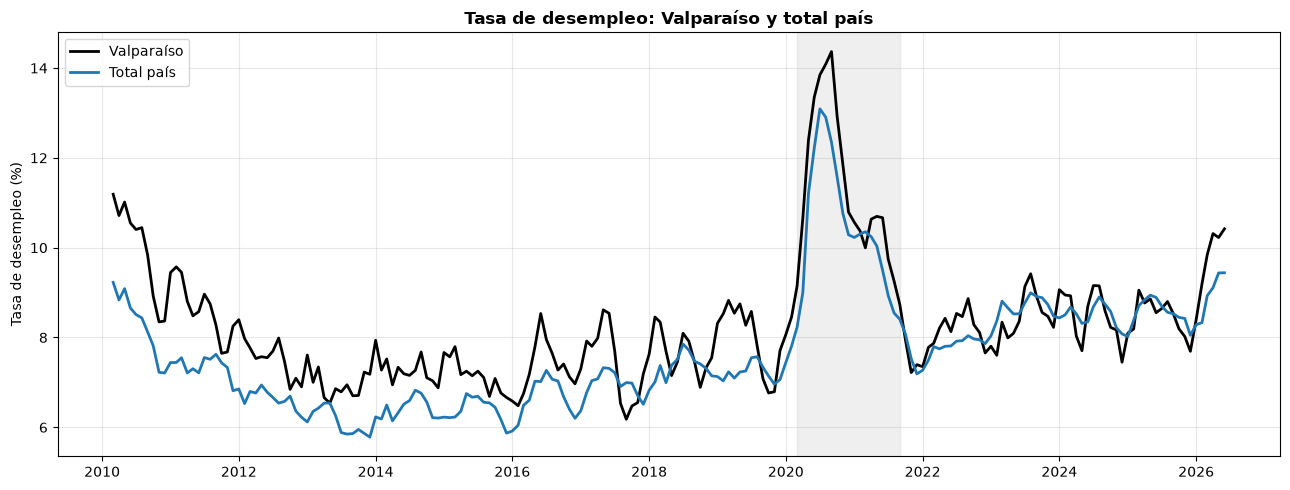

In [7]:
fp.graficar_series(series, titulo='Tasa de desempleo: Valparaíso y total país',
                   sombrear=VENTANA_PANDEMIA);

Se observa que ambas series tienen un comportamiento similar, pero el desempleo en la Región de Valparaíso es mayor que el total nacional. Además, el comportamiento estacional es más evidente en la Región de Valparaíso.

## 3. Estimación de modelos

### 3.1 Orígenes del backtest
El último origen es el último dato menos `H` meses, para que todos los pronósticos puedan compararse con lo observado.

In [8]:
ULTIMO_ORIGEN = serie.index[-1] - pd.DateOffset(months=H)

origenes = pd.date_range(PRIMER_ORIGEN, ULTIMO_ORIGEN, freq='MS')
print(f'{len(origenes)} orígenes: {origenes[0]:%Y-%m} a {origenes[-1]:%Y-%m}, horizonte {H} meses')

43 orígenes: 2022-06 a 2025-12, horizonte 6 meses


### 3.2 Modelos univariados

Emplearemos únicamente la tasa de desempleo disponible hasta cada origen. Los dos benchmarks (naive y naive estacional) se conservan en los gráficos de cada modelo.

#### 3.2.1 AutoARIMA


AutoARIMA: 43 modelos estimados en 71 s


,AutoARIMA
especificacion,
"ARIMA(4,1,0)(1,0,0)[12]",33
"ARIMA(2,1,2)(2,0,0)[12]",5
"ARIMA(3,1,2)(0,0,2)[12]",2
"ARIMA(4,1,0)(2,0,0)[12]",1
"ARIMA(4,1,0)(0,0,2)[12]",1
"ARIMA(6,1,0)(0,0,1)[12]",1


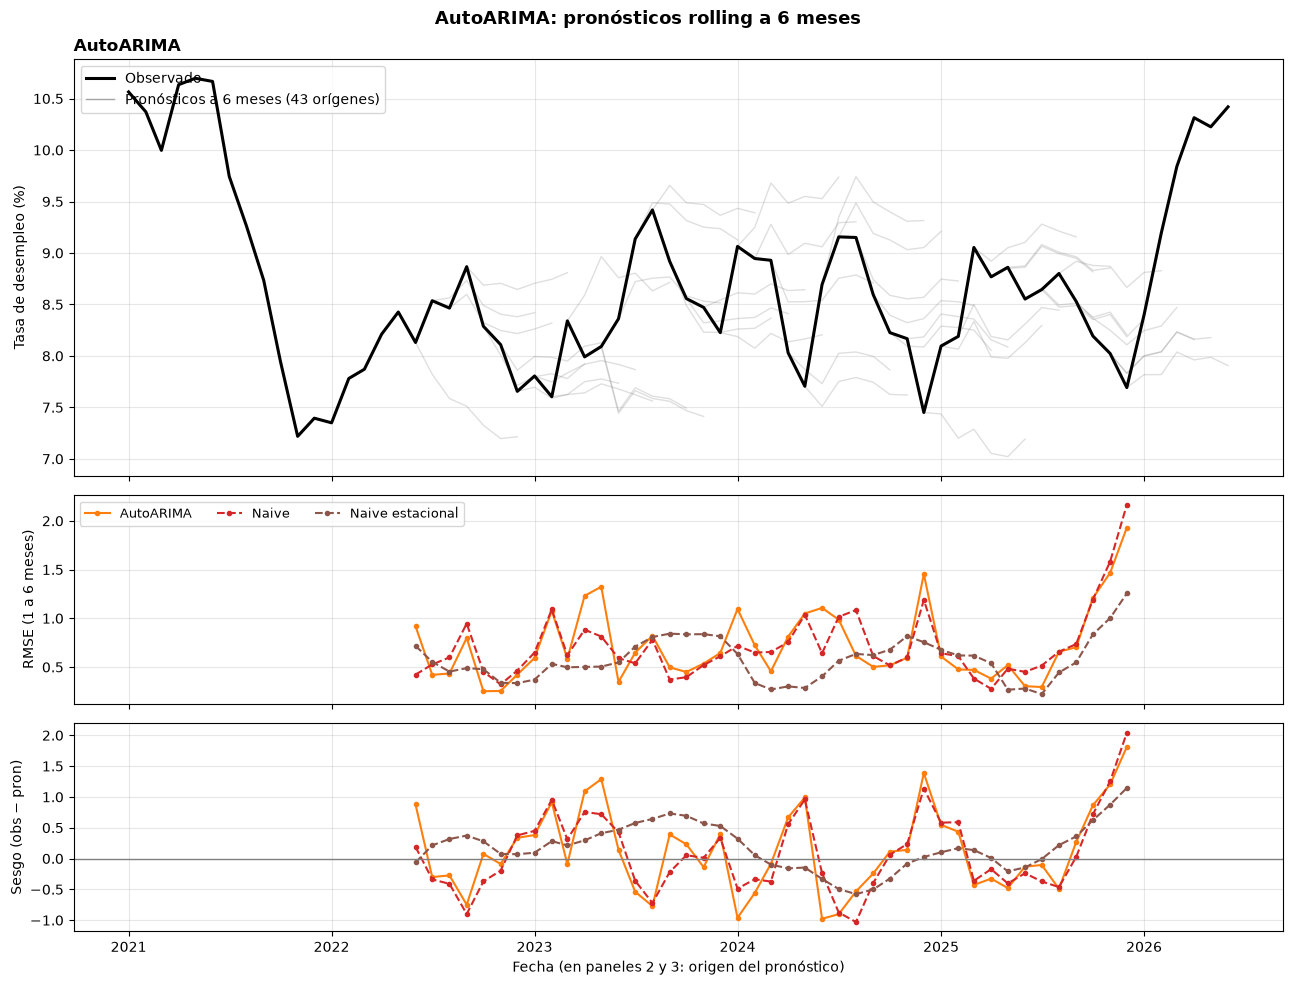

In [9]:
t0 = time.time()
res_arima = fp.pronostico_rolling(serie, ULTIMO_ORIGEN, primer_origen=PRIMER_ORIGEN,
                                  h=H, **PARAMS_ARIMA)
t_arima = time.time() - t0

res_naive = fp.pronostico_rolling_naive(serie, res_arima)
res_naive_estacional = fp.pronostico_rolling_naive(serie, res_arima, estacional=True)
benchmarks = {'Naive': res_naive, 'Naive estacional': res_naive_estacional}

display(res_arima.groupby('origen')['especificacion'].first().value_counts().to_frame('AutoARIMA'))
fp.graficar_modelo(serie, res_arima, referencias=benchmarks, desde='2021-01-01');


Se observa que en 33 de los 43 orígenes se elige la especificación ARIMA(4,1,0)(1,0,0)[12]. Al comparar los pronósticos, se observa que estos se separan bastante del valor real de la serie, lo que se refleja al comparar su RMSE con el del naive estacional.

#### 3.2.2 TimesFM 2.5

Pronóstico univariado sin reentrenar los pesos del modelo. Cada origen utiliza exclusivamente la historia observada hasta ese mes.


TimesFM 2.5: 43 orígenes pronosticados en 5 s


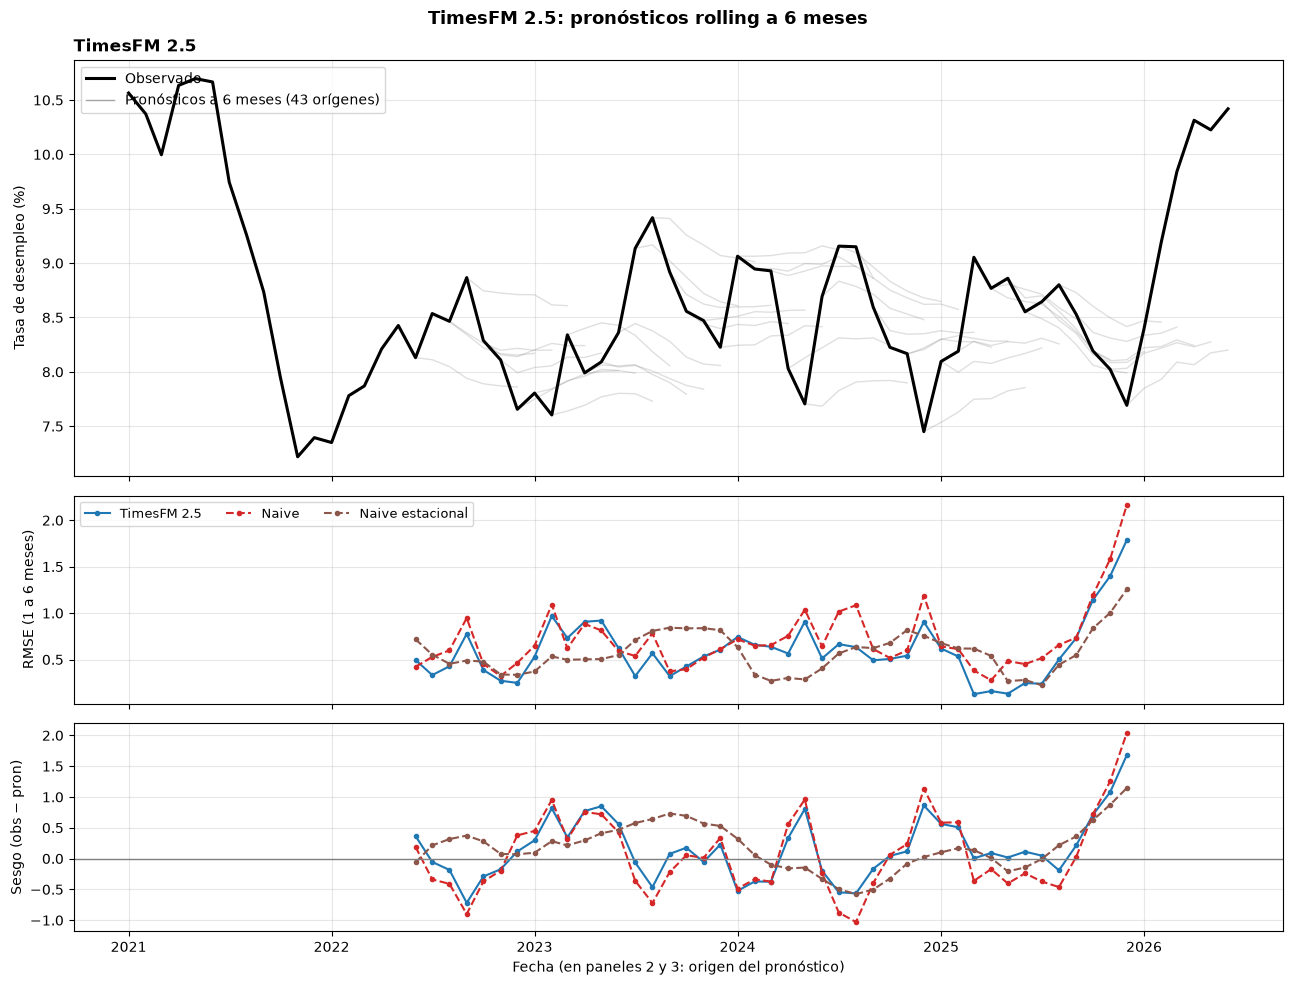

In [10]:
t0 = time.time()
res_tfm25 = fp.pronostico_rolling_timesfm(serie, tfm25, res_arima)
t_tfm25 = time.time() - t0

fp.graficar_modelo(serie, res_tfm25, referencias=benchmarks, desde='2021-01-01');


Se observa que los pronósticos de este modelo se acercan más a los valores observados, pero no logra pronosticar correctamente el alza sostenida de 2026.

#### 3.2.3 TimesFM 3.0

Mismo conjunto de orígenes y horizontes. Se evalúa su salida univariada sin covariables.


TimesFM 3.0: 43 orígenes pronosticados en 5 s


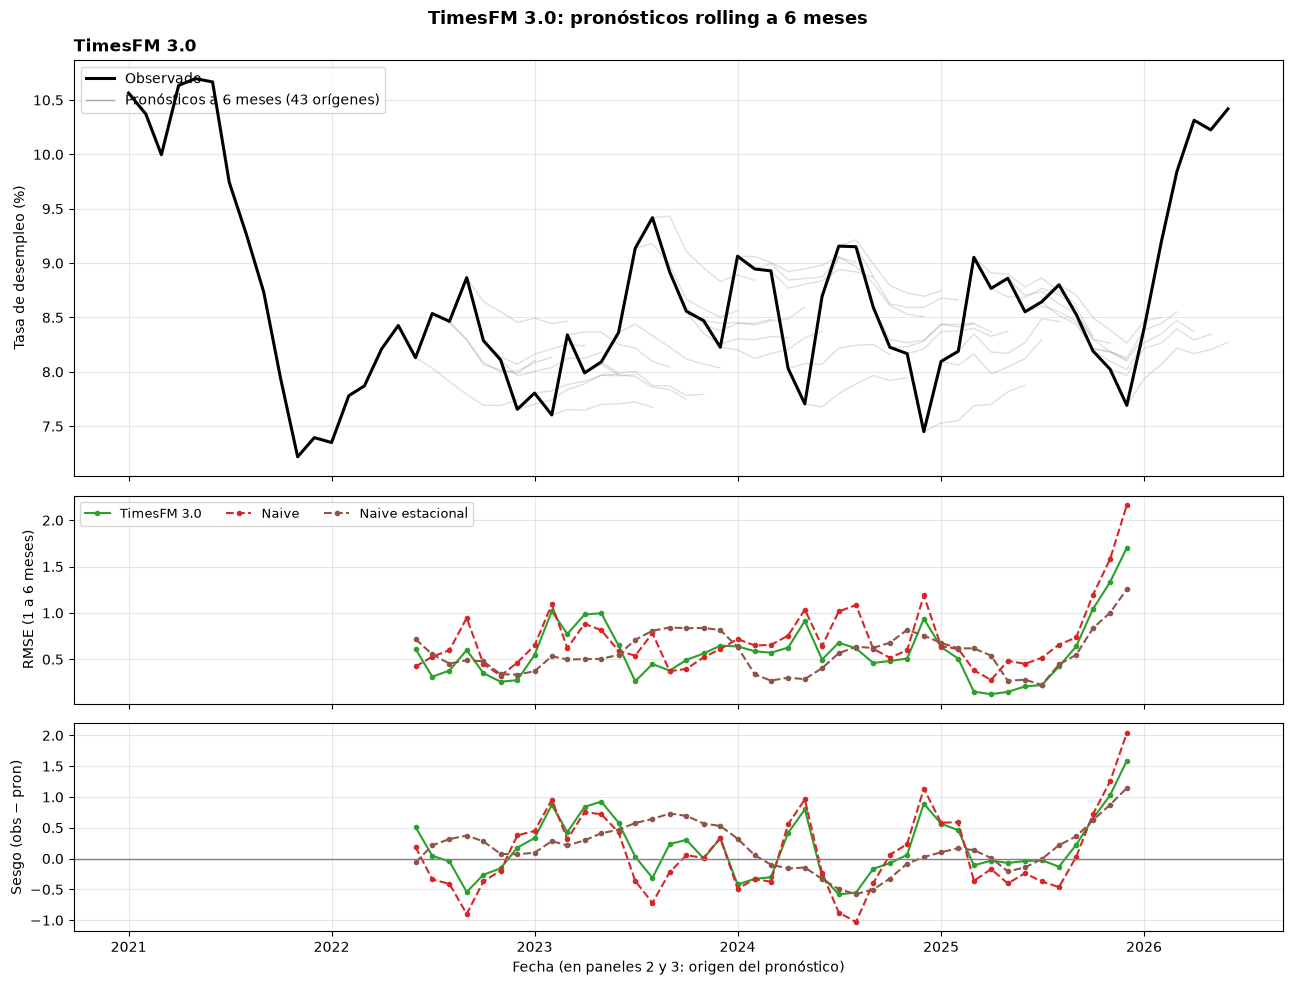

In [11]:
t0 = time.time()
res_tfm3 = fp.pronostico_rolling_timesfm(serie, tfm3, res_arima)
t_tfm3 = time.time() - t0

fp.graficar_modelo(serie, res_tfm3, referencias=benchmarks, desde='2021-01-01');


Este modelo muestra un comportamiento similar al de TimesFM 2.5. En la sección 4 comparo todos los modelos.

### 3.3 Modelos con covariables de intervención

Los tres modelos usan **los mismos 19 pulsos mensuales**, de marzo de 2020 a septiembre de 2021. En cada origen se usan solamente pulsos pasados; para los meses futuros todos valen cero.

Los mecanismos son distintos: AutoARIMAX utiliza regresores exógenos con errores ARIMA; TimesFM 2.5 combina una regresión XReg con pronósticos de TimesFM; TimesFM 3.0 acepta covariables directamente en la red. **No se trata de tres implementaciones equivalentes de una regresión ARIMAX**.

#### 3.3.1 AutoARIMAX


AutoARIMAX: 43 modelos estimados en 103 s


,AutoARIMAX
especificacion,
"Regression with ARIMA(0,1,0) errors",11
"Regression with ARIMA(0,1,0)(2,0,0)[12] errors",10
"Regression with ARIMA(0,1,0)(2,0,1)[12] errors",7
"Regression with ARIMA(0,1,3)(0,0,2)[12] errors",3
"Regression with ARIMA(0,1,0)(0,0,2)[12] errors",3
"Regression with ARIMA(0,1,0)(1,0,0)[12] errors",3
"Regression with ARIMA(0,1,0)(1,0,1)[12] errors",2
"Regression with ARIMA(3,1,0)(2,0,0)[12] errors",1
"Regression with ARIMA(0,1,1)(1,0,2)[12] errors",1


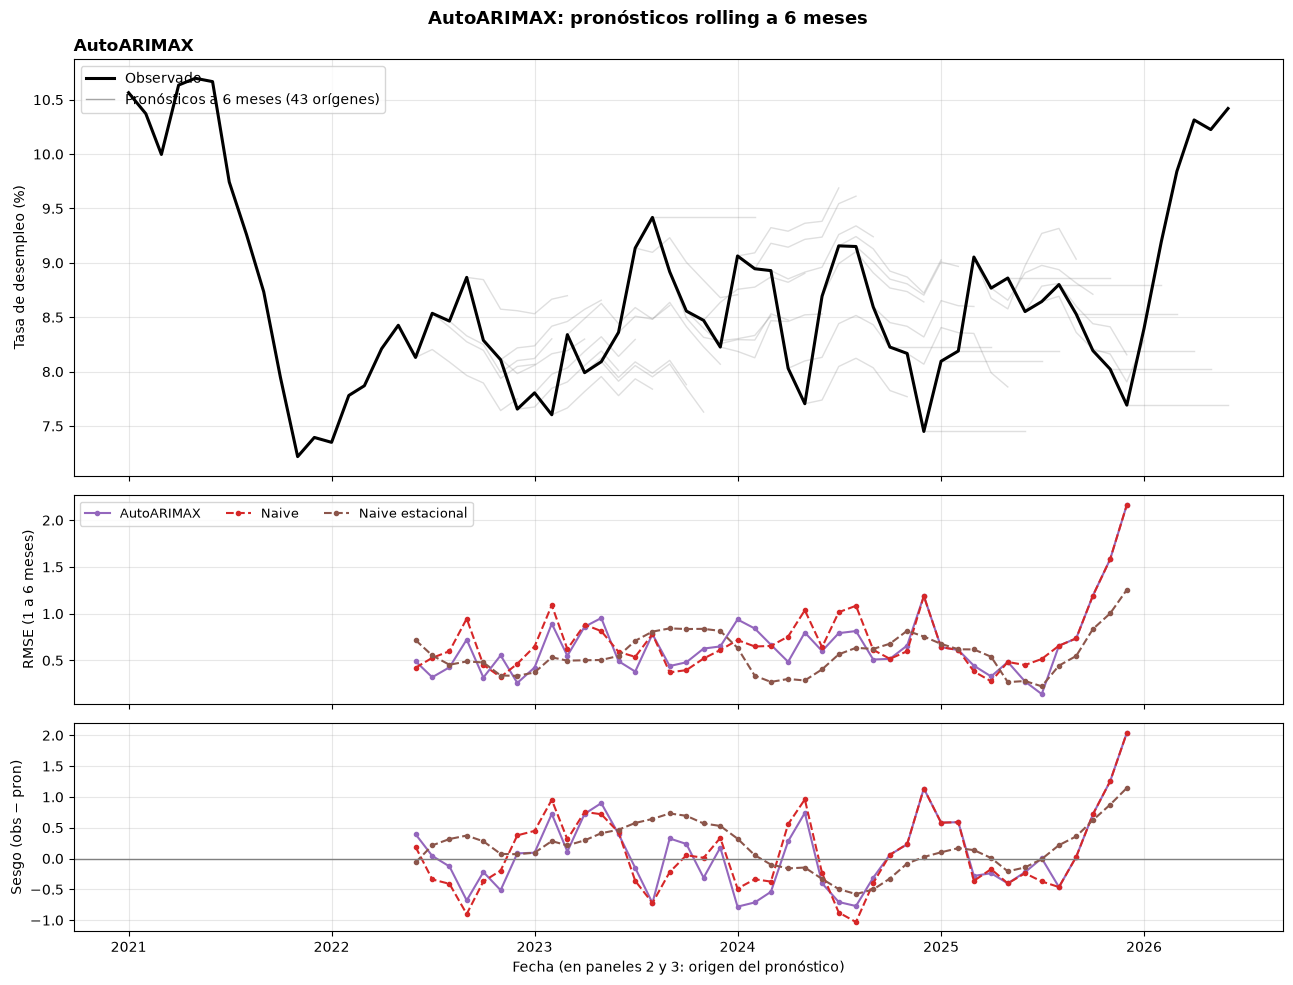

In [12]:
t0 = time.time()
res_arimax = fp.pronostico_rolling(serie, ULTIMO_ORIGEN, primer_origen=PRIMER_ORIGEN,
                                   h=H, ventana_pulsos=VENTANA_PANDEMIA, **PARAMS_ARIMA)
t_arimax = time.time() - t0

display(res_arimax.groupby('origen')['especificacion'].first().value_counts().to_frame('AutoARIMAX'))
fp.graficar_modelo(serie, res_arimax, referencias=benchmarks, desde='2021-01-01');


Acá encontramos una sorpresa: al agregar los pulsos de la pandemia, 37 de los 43 orígenes seleccionan una especificación con errores de tipo paseo aleatorio; en 11 el pronóstico es plano y en 26 aparece un componente estacional. En cambio, AutoARIMA sin esos controles elegía un AR(4) en 33 orígenes. Esto muestra que la especificación automática es sensible al tratamiento de un período extraordinario. No basta, por sí solo, para concluir que los rezagos anteriores estaban capturando exclusivamente la pandemia.

#### 3.3.2 TimesFM 2.5 + pulsos (XReg)

Se aplica `forecast_with_covariates` con `xreg_mode='xreg + timesfm'`: XReg ajusta la serie usando las variables de intervención y TimesFM pronostica la parte residual. Este procedimiento requiere compilar TimesFM 2.5 con `return_backcast=True` y contar con las dependencias de XReg.


TimesFM 2.5 + pulsos: 43 orígenes pronosticados en 7 s


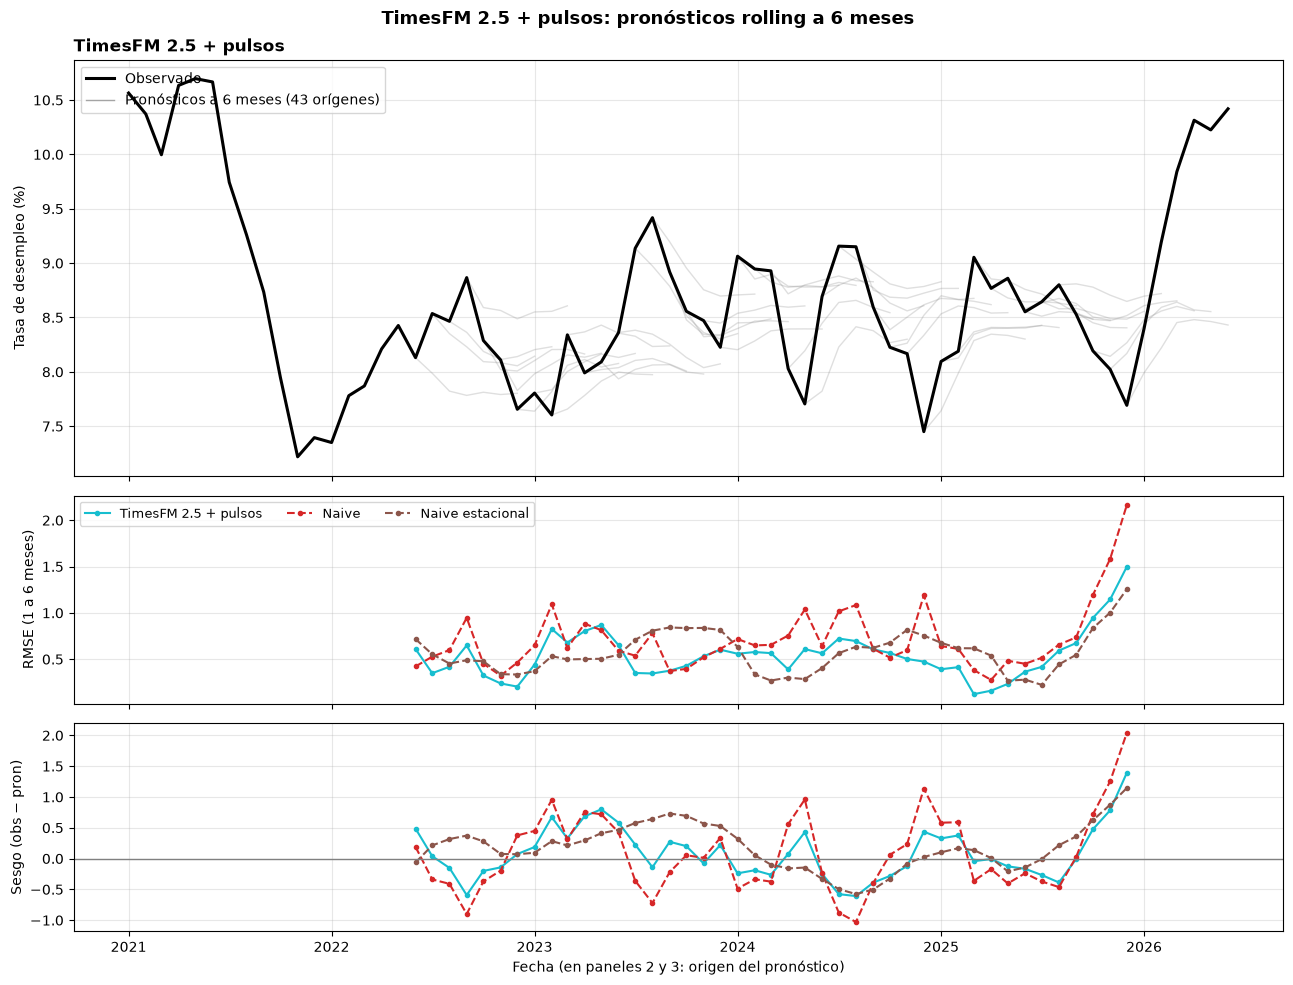

In [13]:
t0 = time.time()
res_tfm25_pulsos = fp.pronostico_rolling_timesfm(
    serie, tfm25, res_arima, ventana_pulsos=VENTANA_PANDEMIA)
t_tfm25_pulsos = time.time() - t0

fp.graficar_modelo(serie, res_tfm25_pulsos, referencias=benchmarks, desde='2021-01-01');


#### 3.3.3 TimesFM 3.0 + pulsos

Las mismas 19 variables se pasan por `past_future_covariates`, con 19 canales y una longitud de historia más horizonte. Esta versión incorpora las covariables de forma nativa.


TimesFM 3.0 + pulsos: 43 orígenes pronosticados en 65 s


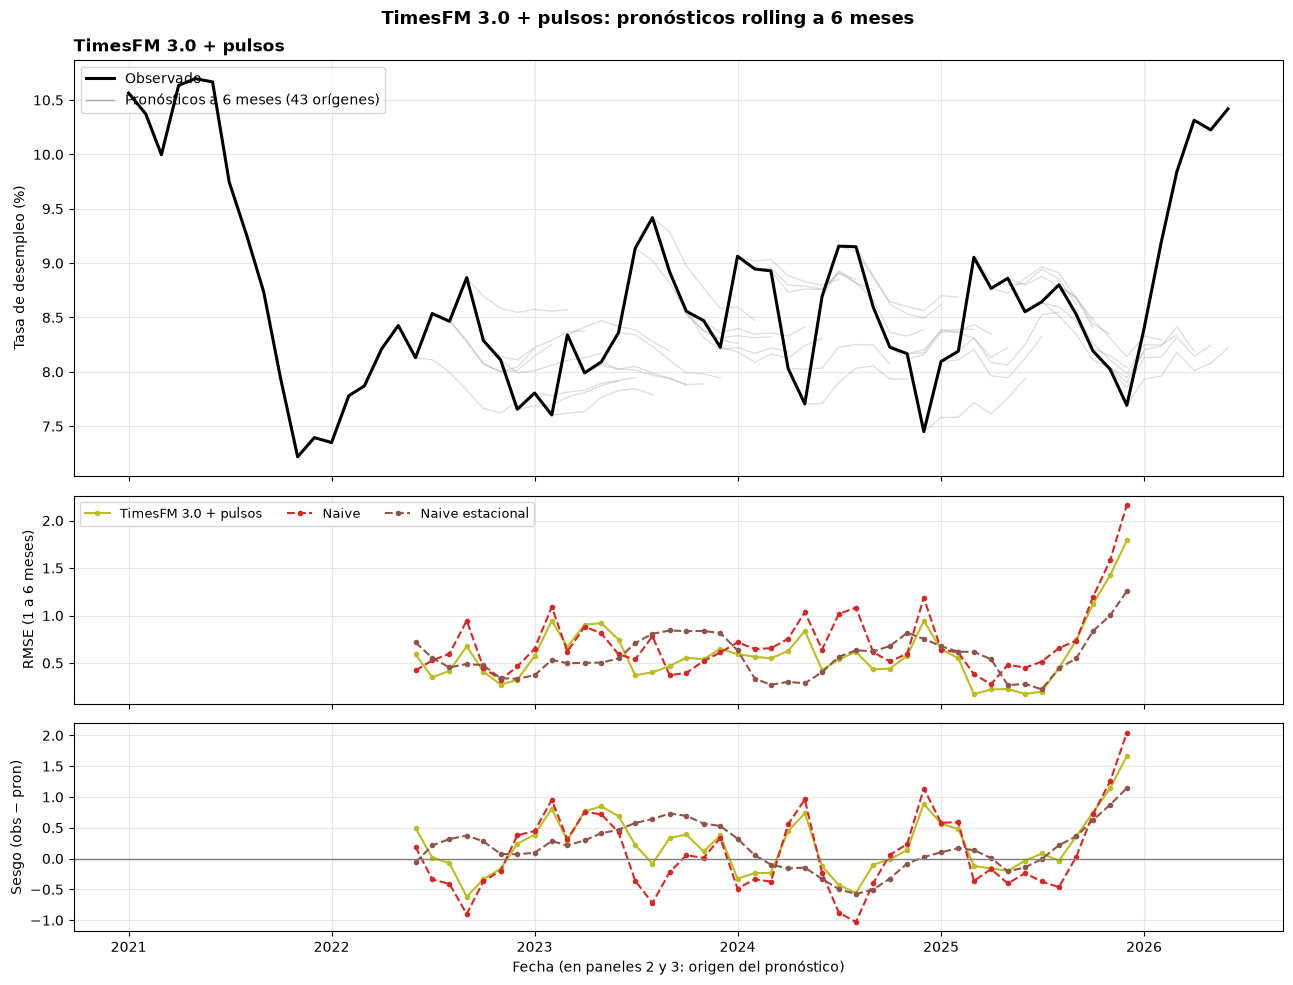

In [14]:
t0 = time.time()
res_tfm3_pulsos = fp.pronostico_rolling_timesfm(
    serie, tfm3, res_arima, ventana_pulsos=VENTANA_PANDEMIA)
t_tfm3_pulsos = time.time() - t0

fp.graficar_modelo(serie, res_tfm3_pulsos, referencias=benchmarks, desde='2021-01-01');


### 3.4 Resultados y tiempos de cómputo

En la siguiente celda registro los tiempos de ejecución de cada modelo, lo que sirve como referencia para su implementación dentro de una empresa.

In [15]:
modelos = {
    'Naive': res_naive,
    'Naive estacional': res_naive_estacional,
    'AutoARIMA': res_arima,
    'TimesFM 2.5': res_tfm25,
    'TimesFM 3.0': res_tfm3,
    'AutoARIMAX': res_arimax,
    'TimesFM 2.5 + pulsos': res_tfm25_pulsos,
    'TimesFM 3.0 + pulsos': res_tfm3_pulsos,
}
fp.guardar_resultados(modelos)

tiempos = pd.Series({
    'AutoARIMA': t_arima,
    'TimesFM 2.5': t_tfm25,
    'TimesFM 3.0': t_tfm3,
    'AutoARIMAX': t_arimax,
    'TimesFM 2.5 + pulsos': t_tfm25_pulsos,
    'TimesFM 3.0 + pulsos': t_tfm3_pulsos,
}, name=f'Tiempo del backtest, {len(origenes)} orígenes (s)')
display(tiempos.round(1))



8 archivos guardados en resultados/


AutoARIMA                71.3
TimesFM 2.5               5.0
TimesFM 3.0               5.0
AutoARIMAX              103.2
TimesFM 2.5 + pulsos      7.6
TimesFM 3.0 + pulsos     65.0
Name: Tiempo del backtest, 43 orígenes (s), dtype: float64

Si observamos los tiempos de ejecución en los 43 orígenes, las versiones univariadas de TimesFM tardaron unos pocos segundos, mientras que AutoARIMA tardó del orden de un minuto. Con los pulsos, los tiempos de TimesFM aumentaron a decenas de segundos, especialmente en TimesFM 3.0, que incluso tardó más que AutoARIMA. AutoARIMAX fue el más exigente en esta ejecución.

Estos tiempos pueden cambiar al repetir el experimento y sirven solo como referencia. Además, AutoARIMA vuelve a estimar sus parámetros en cada origen, mientras que TimesFM realiza inferencia con pesos ya entrenados; por eso no son tareas computacionales exactamente equivalentes.

## 4. Comparación de modelos

### 4.1 RMSE por origen y por horizonte

En primer lugar, comparo el RMSE de cada pronóstico a lo largo del tiempo (un valor por origen) para los benchmarks y los modelos principales.

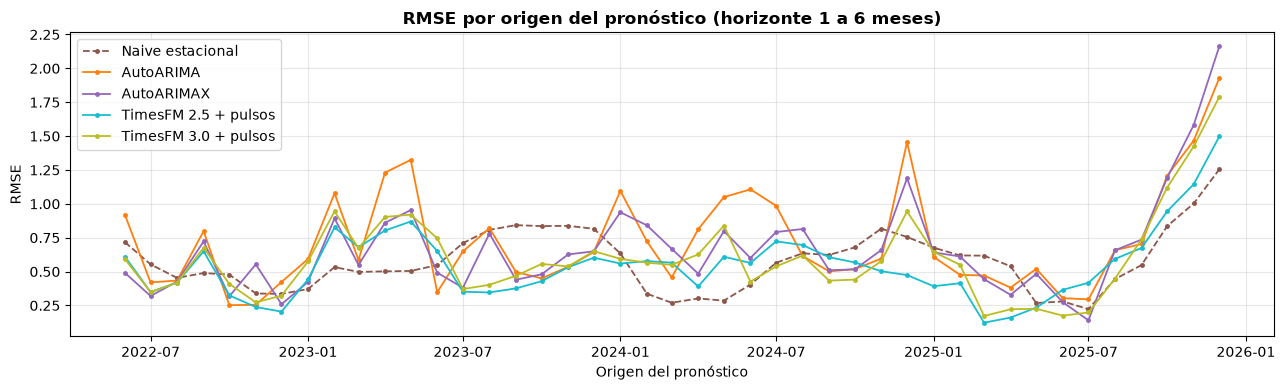

In [16]:
seleccion = ['Naive estacional', 'AutoARIMA', 'AutoARIMAX', 'TimesFM 2.5 + pulsos', 'TimesFM 3.0 + pulsos']
fp.graficar_metrica_por_origen({n: modelos[n] for n in seleccion}, 'RMSE');

Observamos que el naive estacional es el más estable y que los otros modelos solo le ganan en algunos tramos. Los pronósticos hechos a partir de julio de 2025 aumentan su RMSE, lo que indica que ningún modelo logra capturar el alza sostenida del desempleo de 2026.
A continuación comparo el RMSE de todos los modelos por horizonte de pronóstico.

,Naive,Naive estacional,AutoARIMA,TimesFM 2.5,TimesFM 3.0,AutoARIMAX,TimesFM 2.5 + pulsos,TimesFM 3.0 + pulsos,Naive / Naive estacional,AutoARIMA / Naive estacional,TimesFM 2.5 / Naive estacional,TimesFM 3.0 / Naive estacional,AutoARIMAX / Naive estacional,TimesFM 2.5 + pulsos / Naive estacional,TimesFM 3.0 + pulsos / Naive estacional
horizonte,,,,,,,,,,,,,,,
1,0.453,0.581,0.440,0.417,0.402,0.443,0.405,0.400,0.780,0.757,0.717,0.693,0.762,0.698,0.688
2,0.656,0.572,0.668,0.582,0.568,0.620,0.529,0.568,1.146,1.168,1.017,0.993,1.083,0.924,0.994
3,0.835,0.572,0.866,0.712,0.707,0.782,0.616,0.696,1.460,1.515,1.245,1.236,1.368,1.078,1.218
4,0.886,0.618,0.912,0.746,0.727,0.834,0.633,0.734,1.433,1.476,1.206,1.176,1.349,1.024,1.188
5,0.902,0.650,0.924,0.753,0.737,0.852,0.667,0.752,1.387,1.422,1.158,1.134,1.310,1.026,1.157
6,0.930,0.697,0.954,0.800,0.779,0.907,0.716,0.811,1.335,1.370,1.149,1.118,1.302,1.028,1.165


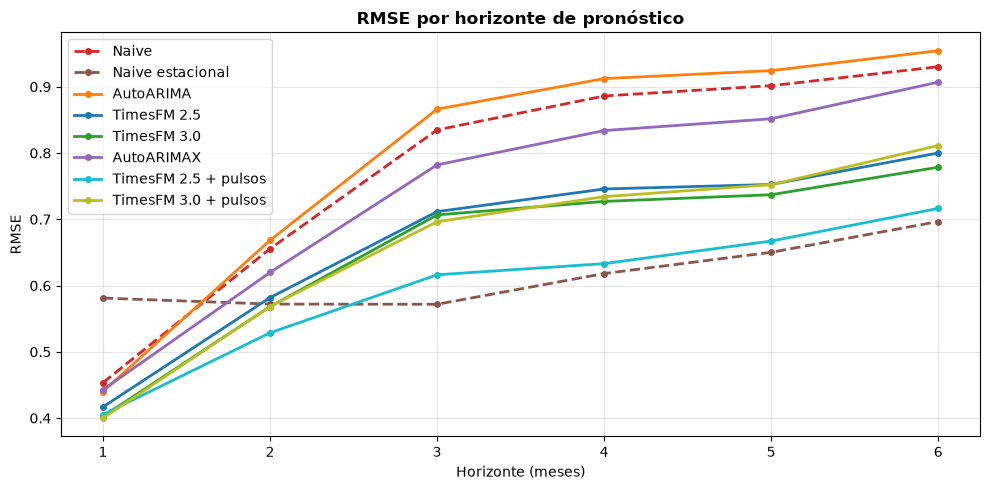

In [17]:
tabla_rmse = fp.comparar_por_horizonte(modelos, 'RMSE', referencia='Naive estacional').round(3)
display(tabla_rmse)

fp.graficar_metrica_por_horizonte(modelos, 'RMSE');

Se observa que TimesFM 2.5 y 3.0 con pulsos le ganan al naive estacional solo hasta el horizonte de 2 meses.
De dos a seis meses, AutoARIMA obtuvo un RMSE mayor incluso que el naive simple, y AutoARIMAX también presentó errores elevados (sin contar los benchmarks). Aun cuando AutoARIMAX eligió en su mayoría paseos aleatorios, obtuvo mejor RMSE que AutoARIMA entre dos y seis meses, lo que sugiere que incorporar los pulsos mejoró sus pronósticos en esos horizontes.
También es importante volver a mencionar que ningún modelo ha podido anticipar el shock reciente del desempleo; esto lo vuelvo a abordar en la sección 4.4.
Otro punto a destacar es que TimesFM 2.5 con pulsos es el que más se acerca al naive estacional, por lo que es plausible explorar aplicaciones más exigentes con este modelo.

### 4.2 Sesgo por horizonte

Ahora analizo el sesgo de los modelos, es decir, si subestiman o sobreestiman el desempleo. Si volvemos a los gráficos de cada modelo, podemos esperar que todos los modelos subestimen.

,Naive,Naive estacional,AutoARIMA,TimesFM 2.5,TimesFM 3.0,AutoARIMAX,TimesFM 2.5 + pulsos,TimesFM 3.0 + pulsos
horizonte,,,,,,,,
1,0.006,0.085,0.027,0.047,0.050,0.010,0.075,0.076
2,0.022,0.136,0.064,0.071,0.115,0.021,0.037,0.141
3,0.054,0.173,0.097,0.112,0.177,0.047,0.039,0.200
4,0.087,0.206,0.139,0.176,0.209,0.072,0.066,0.255
5,0.132,0.230,0.186,0.235,0.249,0.130,0.135,0.295
6,0.186,0.252,0.238,0.314,0.296,0.185,0.184,0.345


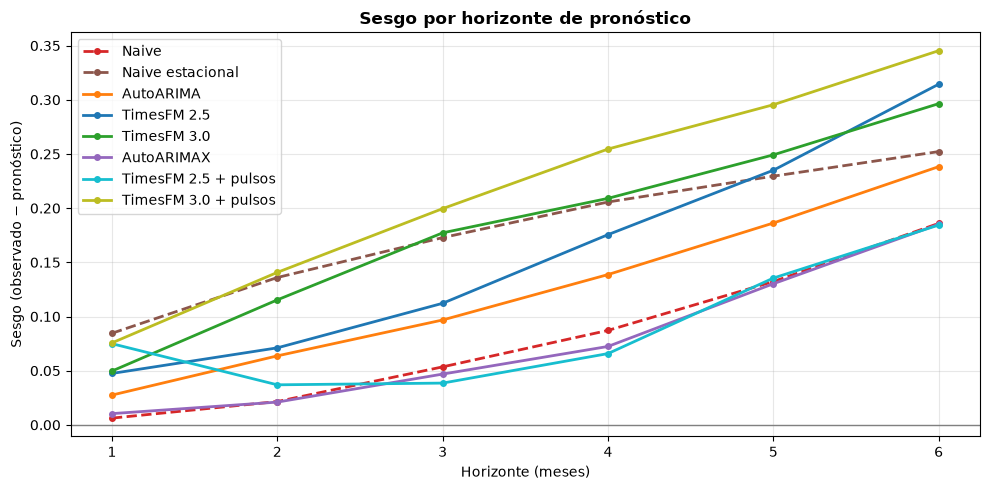

In [18]:
tabla_sesgo = fp.comparar_por_horizonte(modelos, 'Sesgo').round(3)
display(tabla_sesgo)

fp.graficar_metrica_por_horizonte(modelos, 'Sesgo');

Tal como se anticipaba, todos los modelos subestiman el desempleo. AutoARIMAX y TimesFM 2.5 con pulsos tienen un menor sesgo que el naive estacional en todos los horizontes. Aun así, tal como se advirtió con el RMSE, los modelos tienden a subestimar más en 2026, cuando el desempleo empieza a aumentar, lo que sugiere la existencia de un shock al alza.

### 4.3 Período posterior al lanzamiento de TimesFM 2.5

Antes de continuar, retomo una limitación mencionada en la introducción: no tengo un registro completo que permita identificar todas las series y fechas usadas para entrenar TimesFM. Por eso, una buena precisión en el backtest histórico podría estar parcialmente favorecida por información que el modelo ya conocía.

Para reducir ese riesgo, revisé el historial del repositorio de TimesFM 2.5 y separé los pronósticos correspondientes a meses cuya información oficial todavía no existía cuando se actualizaron sus pesos. Es una comprobación adicional, no una garantía de que todo el backtest esté libre de contaminación. Tampoco se puede aplicar el mismo criterio a TimesFM 3.0 con las fechas disponibles en este estudio.

In [19]:
from huggingface_hub import HfApi

api = HfApi()
for repo in (fp.REPO_25, fp.REPO_3):
    print(repo)
    for c in api.list_repo_commits(repo)[:10]:
        print(f'   {c.created_at:%Y-%m-%d}  {c.commit_id[:8]}  {c.title}')

google/timesfm-2.5-200m-pytorch
   2025-10-02  1d952420  Update README.md
   2025-10-01  139be6c9  Update README.md
   2025-10-01  e8ebf27b  Update README.md
   2025-10-01  816f64fb  Update README.md
   2025-10-01  2d1b3206  Update README.md
   2025-10-01  fdcc8eb9  Delete config.yaml
   2025-10-01  d418f3e8  Refreshed model with speed optimizations.
   2025-09-29  a6e2c7cd  Update README.md
   2025-09-26  ef46453a  Remove trailing comma to make it a valid json (#2)
   2025-09-25  9a657df6  Create config.json
google/timesfm-3.0-pytorch
   2026-09-02  43046b85  Test removing timesfm tag to check library_name
   2026-09-01  c7190707  Fix download tracking by removing stale library_name override (defaults to config.json)
   2026-08-31  900fcab4  Update README.md
   2026-08-28  d2741044  Update README.md (#1)
   2026-08-28  3f2c8d24  Update README.md
   2026-08-27  3d64c362  Add license: other (timesfm-non-commercial-license-v1.0) metadata
   2026-08-27  24701cec  Update license to timesfm

El historial muestra una actualización de los pesos de TimesFM 2.5 el **1 de octubre de 2025**; los cambios posteriores que aparecen en la consulta son de documentación. Por eso tomo como ventana de evaluación los **meses objetivo desde octubre de 2025**: la tasa correspondiente a ese trimestre móvil no estaba publicada al momento de esa actualización. Con el checkpoint fijo, esas observaciones posteriores no pudieron estar entre sus valores de entrenamiento.

Este criterio permite hablar de una **ventana posterior a los pesos de TimesFM 2.5**, o «ventana limpia» en ese sentido temporal específico. No certifica qué otras series utilizó el preentrenamiento ni resuelve las limitaciones del backtest histórico completo. **Para TimesFM 3.0 no tengo una ventana equivalente**: sus pesos se publicaron en agosto de 2026 y todos los meses objetivo evaluados aquí son anteriores.

In [20]:
INICIO_POST_TFM25 = '2025-10-01'

limpio = {n: r[r['fecha'] >= INICIO_POST_TFM25] for n, r in modelos.items()}
error = {n: r['observado'] - r['pronostico'] for n, r in limpio.items()}

tabla_limpia = pd.DataFrame({'N': {n: e.count() for n, e in error.items()},
                             'RMSE': {n: np.sqrt((e ** 2).mean()) for n, e in error.items()},
                             'Sesgo': {n: e.mean() for n, e in error.items()}})
tabla_limpia['RMSE / Naive estacional'] = (
    tabla_limpia['RMSE'] / tabla_limpia.loc['Naive estacional', 'RMSE']
)
tabla_limpia.round(3)

,N,RMSE,Sesgo,RMSE / Naive estacional
Naive,39,1.257,0.401,1.639
Naive estacional,39,0.767,0.503,1.000
AutoARIMA,39,1.152,0.465,1.503
TimesFM 2.5,39,1.058,0.530,1.380
TimesFM 3.0,39,0.994,0.480,1.297
AutoARIMAX,39,1.233,0.471,1.609
TimesFM 2.5 + pulsos,39,0.928,0.247,1.210
TimesFM 3.0 + pulsos,39,1.060,0.569,1.383


En esta ventana hay **39 pares de origen y horizonte**, correspondientes a **nueve meses objetivo**, entre octubre de 2025 y junio de 2026. Como varios pronósticos corresponden al mismo mes, no son 39 observaciones independientes.

Ningún modelo supera en RMSE al naive estacional dentro de este subconjunto. TimesFM 2.5 con pulsos presenta el menor sesgo, pero no el menor RMSE. Esta comparación permite observar cómo se comporta TimesFM 2.5 sobre valores que no estaban publicados cuando se fijaron sus pesos; **no permite concluir, a partir de las posiciones relativas, que existió o no contaminación en el resto del backtest**. Además, la ventana coincide en buena parte con el aumento del desempleo de 2026, por lo que la tomo como un resultado complementario.

### 4.4 Desempeño por período: tiempos normales y shock de 2026

Tal como mencioné en celdas anteriores, se observa un alza sostenida del desempleo durante 2026 que ningún modelo logra capturar correctamente, por lo que conviene separar este shock al analizar los resultados. Como el corte se definió después de observar el shock, este análisis es complementario. A continuación separo tanto el RMSE como el sesgo de cada modelo.

In [21]:
CORTE_SHOCK = '2026-01-01'   # meses pronosticados de 2026: salto del desempleo

todo = pd.concat(modelos, names=['nombre']).reset_index(level=0)
todo['error'] = todo['observado'] - todo['pronostico']
todo['periodo'] = np.where(todo['fecha'] >= CORTE_SHOCK, 'Shock 2026', 'Hasta 2025')

rmse = todo.groupby(['nombre', 'periodo'])['error'].apply(lambda e: np.sqrt((e ** 2).mean())).unstack()
print('Pronósticos por período:', todo[todo['nombre'] == 'Naive'].groupby('periodo').size().to_dict())
pd.concat({'RMSE': rmse, 'RMSE / Naive estacional': rmse / rmse.loc['Naive estacional']}, axis=1).round(3)

Pronósticos por período: {'Hasta 2025': 237, 'Shock 2026': 21}


RMSE            RMSE / Naive estacional           
periodo              Hasta 2025 Shock 2026              Hasta 2025 Shock 2026
nombre                                                                       
AutoARIMA                 0.725      1.496                   1.283      1.447
AutoARIMAX                0.630      1.600                   1.114      1.548
Naive                     0.679      1.601                   1.202      1.548
Naive estacional          0.565      1.034                   1.000      1.000
TimesFM 2.5               0.573      1.410                   1.014      1.364
TimesFM 2.5 + pulsos      0.526      1.159                   0.931      1.121
TimesFM 3.0               0.571      1.329                   1.011      1.286
TimesFM 3.0 + pulsos      0.561      1.429                   0.992      1.382

Se observa que, en el período previo a 2026, TimesFM 2.5 y 3.0 con pulsos le ganan al naive estacional; TimesFM 2.5 y 3.0 sin pulsos quedan apenas por encima, y AutoARIMA y AutoARIMAX quedan claramente por encima.
Por otro lado, para los pronósticos de 2026, ningún modelo le gana al naive estacional.
A continuación analizo de igual forma el sesgo de cada modelo.

In [22]:
sesgo = todo.groupby(['nombre', 'periodo'])['error'].mean().unstack().reindex(list(modelos))
sesgo.round(3)

periodo,Hasta 2025,Shock 2026
nombre,,
Naive,-0.024,1.269
Naive estacional,0.115,0.915
AutoARIMA,0.027,1.236
TimesFM 2.5,0.069,1.183
TimesFM 3.0,0.102,1.096
AutoARIMAX,-0.029,1.286
TimesFM 2.5 + pulsos,0.019,0.887
TimesFM 3.0 + pulsos,0.130,1.214


Se observa que el sesgo de los modelos es cercano a cero hasta 2025, y en ese período todos los modelos, salvo TimesFM 3.0 con pulsos, tienen un sesgo menor que el naive estacional. En 2026, en cambio, todos subestiman en casi un punto o más, y solo TimesFM 2.5 con pulsos tiene un sesgo algo menor que el naive estacional. TimesFM 2.5 con pulsos es el modelo con menor sesgo en ambos tramos.

A continuación se muestran de forma gráfica el RMSE y el sesgo de cada modelo.

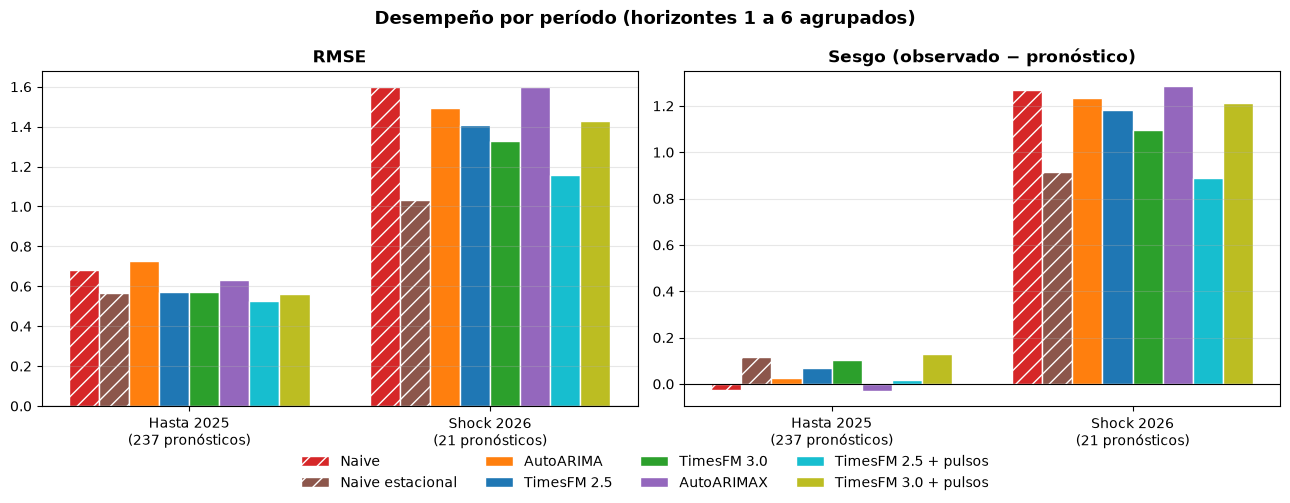

In [23]:
metricas = (todo.groupby(['nombre', 'periodo'])['error']
                .agg(RMSE=lambda e: np.sqrt((e ** 2).mean()), Sesgo='mean'))
n_obs = todo[todo['nombre'] == 'Naive'].groupby('periodo').size()
periodos = ['Hasta 2025', 'Shock 2026']
x = np.arange(len(periodos))
ancho = 0.8 / len(modelos)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metrica in zip(ejes, ['RMSE', 'Sesgo']):
    for i, nombre in enumerate(modelos):
        valores = metricas.loc[nombre, metrica].reindex(periodos)
        ax.bar(x + i * ancho, valores, width=ancho, color=fp.COLORES.get(nombre, 'gray'),
               hatch='//' if nombre.startswith('Naive') else None, edgecolor='white', label=nombre)
    ax.set_xticks(x + ancho * (len(modelos) - 1) / 2)
    ax.set_xticklabels([f'{p}\n({n_obs[p]} pronósticos)' for p in periodos])
    ax.set_title(metrica if metrica == 'RMSE' else 'Sesgo (observado − pronóstico)', fontweight='bold')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(axis='y', alpha=0.3)

handles, etiquetas = ejes[0].get_legend_handles_labels()
fig.legend(handles, etiquetas, loc='lower center', ncol=4, frameon=False)
fig.suptitle('Desempeño por período (horizontes 1 a 6 agrupados)', fontweight='bold', fontsize=13)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Se observa que el RMSE casi se duplica en 2026 respecto del período anterior. Por otro lado, el sesgo, cercano a cero hasta 2025, sube a casi un punto o más en 2026. Esto sugiere que ningún modelo es capaz de capturar el shock actual del desempleo.
A continuación, para cerrar las comparaciones, cuento para cada modelo las veces que le ganó al naive estacional, tanto en RMSE como en sesgo, en los pronósticos de cada origen (horizontes 1 a 6). Si bien esto no constituye un test formal, es un indicador fácil de explicar.

In [24]:
ref = fp.metricas_por_origen(modelos['Naive estacional'])

victorias = {}
for nombre, res in modelos.items():
    if nombre == 'Naive estacional':
        continue
    m = fp.metricas_por_origen(res).reindex(ref.index)
    gana_rmse = m['RMSE'] < ref['RMSE']
    gana_sesgo = m['Sesgo'].abs() < ref['Sesgo'].abs()
    victorias[nombre] = {'Orígenes': len(m),
                         'Gana en RMSE': gana_rmse.sum(), '% RMSE': 100 * gana_rmse.mean(),
                         'Gana en |sesgo|': gana_sesgo.sum(), '% |sesgo|': 100 * gana_sesgo.mean()}

pd.DataFrame(victorias).T.round(0).astype(int)

,Orígenes,Gana en RMSE,% RMSE,Gana en |sesgo|,% |sesgo|
Naive,43,17,40,10,23
AutoARIMA,43,18,42,15,35
TimesFM 2.5,43,22,51,17,40
TimesFM 3.0,43,24,56,19,44
AutoARIMAX,43,21,49,15,35
TimesFM 2.5 + pulsos,43,22,51,20,47
TimesFM 3.0 + pulsos,43,25,58,18,42


Se observa que TimesFM 2.5 y 3.0 con pulsos apenas logran superar al naive estacional en el 51% y el 58% de los orígenes, respectivamente, y que en sesgo ningún modelo supera al naive estacional en más del 50% de los orígenes.

## 5. Test de Diebold-Mariano

Con los pronósticos ya hechos, es necesario evaluar si estas diferencias son aleatorias o estadísticamente significativas; para esto utilizo el test de Diebold-Mariano. Este test compara la precisión de dos modelos para un horizonte dado y responde si la diferencia de error entre ellos es estadísticamente significativa o puede atribuirse al azar. En cada origen se calcula la diferencia entre los errores al cuadrado de ambos modelos; si los modelos fueran igual de precisos, el promedio de esa diferencia sería cero. Como los pronósticos de orígenes consecutivos se traslapan, la varianza considera la autocorrelación hasta el rezago h−1, y el estadístico se corrige para muestras pequeñas (Harvey, Leybourne y Newbold, 1997).

Comparo cada modelo contra el naive estacional, que es el benchmark principal, y agrego tres preguntas puntuales: si la intervención aporta en AutoARIMA (AutoARIMAX contra AutoARIMA), si TimesFM supera a AutoARIMA (con y sin pulsos) y si TimesFM 3.0 es mejor que la 2.5 (con y sin pulsos). No aplico ajuste por comparaciones múltiples, por lo que busco patrones a través de los horizontes y no valores p aislados. Un valor p alto no significa que los modelos sean iguales, sino que con estos datos no se pueden distinguir.

Dado que se hacen varios tests de Diebold-Mariano, preparé una tabla que, para cada par de modelos y horizonte, muestra el estadístico de Diebold-Mariano, el valor p entre paréntesis, asteriscos según su significancia y el modelo ganador cuando la diferencia es significativa.

In [25]:
pares = [(m, 'Naive estacional') for m in modelos if m != 'Naive estacional'] + [
    ('AutoARIMAX', 'AutoARIMA'),                  # ¿aporta la intervención en ARIMA?
    ('TimesFM 2.5', 'AutoARIMA'),                        # IA vs. econometría automática 
    ('TimesFM 2.5 + pulsos', 'AutoARIMAX'),              # IA vs. econometría automática ambas con intervención
    ('TimesFM 3.0', 'TimesFM 2.5'),                      # vale la pena la versión de pago?
    ('TimesFM 3.0 + pulsos', 'TimesFM 2.5 + pulsos'),    # ¿vale la pena la versión de pago? (ahora con intervención)
]
tabla_dm = fp.tabla_diebold_mariano(modelos, pares)
estrellas = pd.cut(tabla_dm['p_valor'], [0, 0.01, 0.05, 0.10, 1.01],
                   labels=['***', '**', '*', ''], right=False).astype(str)


tabla_dm['resultado'] = (tabla_dm['DM'].map('{:.2f}'.format) + ' ('
                         + tabla_dm['p_valor'].map('{:.3f}'.format) + ')' + estrellas
                         + np.where(tabla_dm['p_valor'] < 0.10,
                                    '<br><small>' + tabla_dm['mejor'] + '</small>',
                                    '<br><small>&nbsp;</small>'))

display(tabla_dm.pivot(index='comparacion', columns='horizonte', values='resultado')
                .loc[list(dict.fromkeys(tabla_dm['comparacion']))]
                .style.set_properties(**{'text-align': 'center'})
                .set_caption('Estadístico DM (valor p) y modelo ganador cuando la diferencia es significativa. '
                             'DM negativo: el primer modelo se equivoca menos. '
                             '*** p < 0,01; ** p < 0,05; * p < 0,10.'))

horizonte,1,2,3,4,5,6
comparacion,,,,,,
Naive vs Naive estacional,-1.62 (0.113),0.82 (0.417),2.82 (0.007)***Naive estacional,2.18 (0.035)**Naive estacional,1.64 (0.109),1.53 (0.134)
AutoARIMA vs Naive estacional,-1.82 (0.076)*AutoARIMA,0.91 (0.367),2.85 (0.007)***Naive estacional,2.99 (0.005)***Naive estacional,2.80 (0.008)***Naive estacional,2.53 (0.015)**Naive estacional
TimesFM 2.5 vs Naive estacional,-2.08 (0.044)**TimesFM 2.5,0.10 (0.922),1.55 (0.128),1.25 (0.217),0.85 (0.401),0.87 (0.387)
TimesFM 3.0 vs Naive estacional,-2.31 (0.026)**TimesFM 3.0,-0.04 (0.967),1.50 (0.141),1.12 (0.270),0.76 (0.452),0.81 (0.422)
AutoARIMAX vs Naive estacional,-1.77 (0.083)*AutoARIMAX,0.48 (0.632),2.08 (0.044)**Naive estacional,1.79 (0.080)*Naive estacional,1.39 (0.172),1.52 (0.136)
TimesFM 2.5 + pulsos vs Naive estacional,-2.35 (0.023)**TimesFM 2.5 + pulsos,-0.47 (0.638),0.52 (0.605),0.18 (0.859),0.20 (0.844),0.30 (0.764)
TimesFM 3.0 + pulsos vs Naive estacional,-2.33 (0.025)**TimesFM 3.0 + pulsos,-0.04 (0.968),1.47 (0.148),1.17 (0.249),0.80 (0.431),0.87 (0.389)
AutoARIMAX vs AutoARIMA,0.08 (0.939),-1.07 (0.289),-1.68 (0.100)*AutoARIMAX,-1.46 (0.151),-1.54 (0.131),-1.06 (0.295)
TimesFM 2.5 vs AutoARIMA,-0.69 (0.493),-2.25 (0.029)**TimesFM 2.5,-4.60 (0.000)***TimesFM 2.5,-4.47 (0.000)***TimesFM 2.5,-7.91 (0.000)***TimesFM 2.5,-4.23 (0.000)***TimesFM 2.5


La tabla anterior puede ser un poco compleja de interpretar, pero nos entrega información valiosa.

Al comparar AutoARIMA contra el naive estacional, observamos que el signo del estadístico es negativo solo en el horizonte 1: AutoARIMA es más preciso solo a 1 mes, y apenas con una significancia del 10%. En los horizontes 3 a 6, en cambio, el naive estacional es más preciso, con una significancia del 1% al 5%. Algo similar ocurre con el naive simple y con AutoARIMAX, aunque con menor significancia.

Los modelos TimesFM, con y sin pulsos, le ganan al naive estacional a 1 mes, con una significancia del 5%. Desde el horizonte 2 no se observan diferencias significativas, por lo que no podemos distinguirlos del naive estacional.

**Donde se encuentra una gran diferencia es al comparar TimesFM 2.5 con AutoARIMA, y TimesFM 2.5 + pulsos con AutoARIMAX:** en ambos casos, TimesFM es superior. La evidencia más fuerte está en la comparación univariada, donde TimesFM 2.5 le gana a AutoARIMA de 2 a 6 meses, con valores p menores a 0,001 de 3 a 6 meses. Con pulsos, TimesFM 2.5 le gana a AutoARIMAX al 5% a 3 y 4 meses, y al 10% a 2, 5 y 6 meses.

Al comparar TimesFM 2.5 con 3.0, tanto en las versiones con pulsos como en las sin pulsos, solo se observa una ventaja débil (al 10%) para TimesFM 3.0 en el horizonte 1 de la versión sin pulsos, por lo que no podemos determinar qué versión de TimesFM tiene mejor desempeño.

## 6. Pronóstico hacia adelante: julio a diciembre de 2026


Para este experimento utilicé la versión de la serie ENE que tenía disponible hasta **junio de 2026** y conservé ese corte para generar los pronósticos de julio a diciembre. Más adelante descargué observaciones de julio, agosto y septiembre y las usé para una comprobación complementaria, sin reestimar los modelos.

Es importante distinguir el **origen estadístico del pronóstico (junio)** de su **fecha efectiva de cálculo**: cuando un pronóstico se reconstruye después de publicarse el dato observado, es una evaluación retrospectiva con corte histórico, no una predicción registrada en tiempo real.

In [26]:
FECHA_PRONOSTICO = pd.Timestamp.today().strftime('%Y-%m-%d')
orden = list(modelos)

adelante = pd.concat({region: fp.pronosticos_adelante(series[region], H, modelos_timesfm=[tfm25, tfm3],
                                                      ventana_pulsos=VENTANA_PANDEMIA, **PARAMS_ARIMA)
                      for region in ['Valparaíso', 'Total país']},
                     names=['region']).reset_index(level=0)
adelante['fecha_pronostico'] = FECHA_PRONOSTICO
adelante.to_csv(f'resultados/pronostico_adelante_{FECHA_PRONOSTICO}.csv', index=False)

(adelante.pivot_table(index=['region', 'fecha'], columns='modelo', values='pronostico')
         .reindex(columns=orden).round(2))

modelo                 Naive  Naive estacional  AutoARIMA  TimesFM 2.5  \
region     fecha                                                         
Total país 2026-07-01   9.44              8.70       9.53         9.58   
           2026-08-01   9.44              8.56       9.46         9.49   
           2026-09-01   9.44              8.53       9.43         9.44   
           2026-10-01   9.44              8.45       9.34         9.27   
           2026-11-01   9.44              8.42       9.25         9.11   
           2026-12-01   9.44              8.05       9.13         8.92   
Valparaíso 2026-07-01  10.42              8.64      10.39        10.50   
           2026-08-01  10.42              8.80      10.56        10.30   
           2026-09-01  10.42              8.53      10.43        10.02   
           2026-10-01  10.42              8.19      10.41         9.74   
           2026-11-01  10.42              8.02      10.32         9.54   
           2026-12-01  10.42              7.69      10.28         9.45   

modelo                 TimesFM 3.0  AutoARIMAX  TimesFM 2.5 + pulsos  \
region     fecha                                                       
Total país 2026-07-01         9.53        9.53                  9.40   
           2026-08-01         9.42        9.44                  9.29   
           2026-09-01         9.36        9.32                  9.21   
           2026-10-01         9.21        9.22                  9.12   
           2026-11-01         9.05        9.13                  9.02   
           2026-12-01         8.87        9.01                  8.95   
Valparaíso 2026-07-01        10.37       10.42                 10.30   
           2026-08-01        10.19       10.42                 10.12   
           2026-09-01         9.96       10.42                  9.88   
           2026-10-01         9.70       10.42                  9.68   
           2026-11-01         9.55       10.42                  9.63   
           2026-12-01         9.50       10.42                  9.65   

modelo                 TimesFM 3.0 + pulsos  
region     fecha                             
Total país 2026-07-01                  9.50  
           2026-08-01                  9.43  
           2026-09-01                  9.35  
           2026-10-01                  9.20  
           2026-11-01                  9.04  
           2026-12-01                  8.88  
Valparaíso 2026-07-01                 10.37  
           2026-08-01                 10.24  
           2026-09-01                  9.99  
           2026-10-01                  9.65  
           2026-11-01                  9.50  
           2026-12-01                  9.32

In [27]:
fp.pronostico_un_origen(series['Valparaíso'], series['Valparaíso'].index[-1], h=H,
                        ventana_pulsos=VENTANA_PANDEMIA, **PARAMS_ARIMA)['especificacion'].iloc[0]

'Regression with ARIMA(0,1,0) errors'

Al revisar los pronósticos, llama la atención que, para la Región de Valparaíso, AutoARIMAX eligió un paseo aleatorio simple, por lo que su pronóstico coincide con el naive. Esto está en línea con lo observado en el backtest, donde la mayoría de los modelos elegidos por AutoARIMAX fueron paseos aleatorios.

En el siguiente gráfico se muestran las trayectorias proyectadas de julio a diciembre de 2026 desde el corte de junio, tanto para la Región de Valparaíso como para el total nacional. El naive estacional proyecta la caída más fuerte, porque repite los niveles de 2025. Para Valparaíso, AutoARIMAX mantiene constante el último valor, igual que el naive; los demás modelos muestran trayectorias de distinta magnitud.

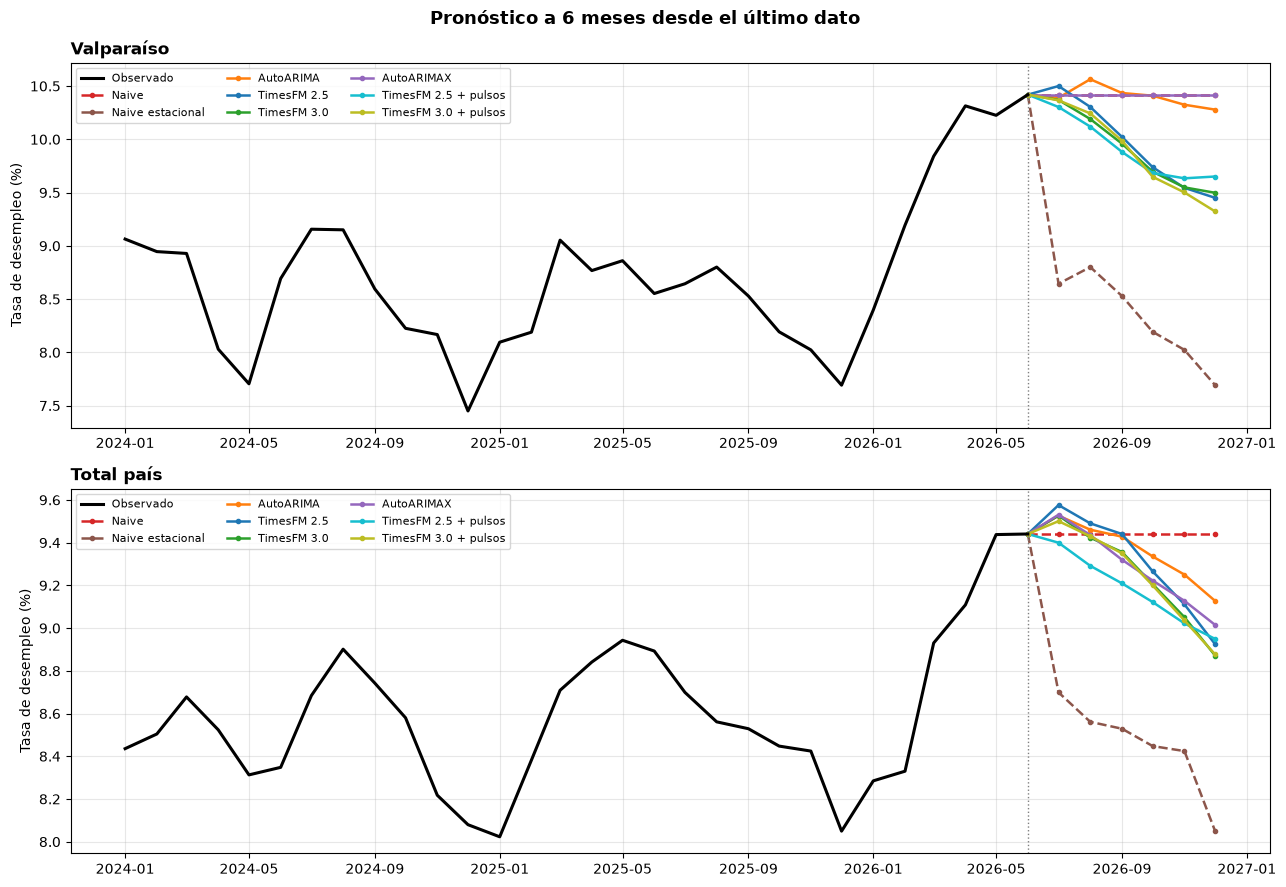

In [28]:
fp.graficar_adelante({r: series[r] for r in ['Valparaíso', 'Total país']}, adelante,
                     desde='2024-01-01');

### 6.1 Evaluación con julio, agosto y septiembre de 2026

En esta sección comparo las proyecciones calculadas con el corte de junio frente a **tres meses objetivo: julio, agosto y septiembre de 2026**, tanto para Valparaíso como para el total nacional. Los valores observados provienen de una versión actualizada de los microdatos de la ENE y los modelos no se reestimaron. La comparación utiliza los tres meses disponibles para esta evaluación y, por su tamaño reducido, los resultados deben considerarse preliminares.

In [29]:
ARCHIVO_ACTUALIZADO = 'serie_desempleo_regional_actualizado.csv'

if os.path.exists(ARCHIVO_ACTUALIZADO):
    reales = fp.cargar_series_regionales(ARCHIVO_ACTUALIZADO, regiones=(5, 99))
    evaluacion = adelante.copy()
    evaluacion['observado'] = [reales[r].get(f) for r, f in zip(evaluacion['region'], evaluacion['fecha'])]
    evaluacion = evaluacion.dropna(subset=['observado'])
    evaluacion['error'] = evaluacion['observado'] - evaluacion['pronostico']

    display(evaluacion.pivot_table(index=['region', 'fecha'], columns='modelo', values='error')
                      .reindex(columns=orden).round(2))
    rmse_adelante = (evaluacion.groupby(['region', 'modelo'])['error']
                              .apply(lambda e: np.sqrt((e ** 2).mean())).unstack()
                              .reindex(columns=orden))
    display(rmse_adelante.round(3))
else:
    print(f'Pendiente: agregar {ARCHIVO_ACTUALIZADO} para evaluar los pronósticos.')


modelo                 Naive  Naive estacional  AutoARIMA  TimesFM 2.5  \
region     fecha                                                         
Total país 2026-07-01   0.09              0.83       0.00        -0.05   
           2026-08-01   0.20              1.08       0.18         0.15   
           2026-09-01   0.36              1.27       0.37         0.36   
Valparaíso 2026-07-01  -0.04              1.74      -0.01        -0.12   
           2026-08-01  -0.20              1.41      -0.35        -0.09   
           2026-09-01  -0.54              1.35      -0.55        -0.14   

modelo                 TimesFM 3.0  AutoARIMAX  TimesFM 2.5 + pulsos  \
region     fecha                                                       
Total país 2026-07-01         0.00       -0.00                  0.13   
           2026-08-01         0.22        0.20                  0.35   
           2026-09-01         0.45        0.48                  0.59   
Valparaíso 2026-07-01         0.01       -0.04                  0.08   
           2026-08-01         0.03       -0.20                  0.10   
           2026-09-01        -0.08       -0.54                 -0.00   

modelo                 TimesFM 3.0 + pulsos  
region     fecha                             
Total país 2026-07-01                  0.03  
           2026-08-01                  0.21  
           2026-09-01                  0.45  
Valparaíso 2026-07-01                  0.01  
           2026-08-01                 -0.03  
           2026-09-01                 -0.11

modelo,Naive,Naive estacional,AutoARIMA,TimesFM 2.5,TimesFM 3.0,AutoARIMAX,TimesFM 2.5 + pulsos,TimesFM 3.0 + pulsos
region,,,,,,,,
Total país,0.244,1.076,0.240,0.228,0.287,0.303,0.404,0.289
Valparaíso,0.333,1.510,0.378,0.118,0.048,0.333,0.071,0.063


Al revisar los resultados preliminares, encontramos que el naive estacional es el modelo con peor desempeño en ambas series (RMSE de 1,076 en el total país y de 1,510 en Valparaíso), porque repite el nivel de 2025, cuando el desempleo era más bajo. El resto de los modelos tuvo errores menores.

En el total país, TimesFM 2.5 (RMSE de 0,228) y AutoARIMA (0,240) son los que tienen menor error y le ganan por poco al naive simple (0,244). Los demás modelos, incluidos TimesFM 3.0 y las versiones con pulsos, quedaron por encima del naive simple. En la Región de Valparaíso, TimesFM 3.0 sin pulsos tuvo el menor RMSE (0,048), seguido de TimesFM 3.0 con pulsos y TimesFM 2.5 con pulsos. Todos los modelos TimesFM le ganaron al naive simple; AutoARIMAX lo igualó (su pronóstico es el mismo) y AutoARIMA obtuvo un error mayor.

Con solo tres meses, estas diferencias no permiten establecer un ranking definitivo, pero sí muestran algo relevante: el naive estacional, que fue muy competitivo en el backtest histórico, es frágil ante un cambio de nivel. Por eso conviene evaluar siempre contra ambos benchmarks.

## 7. Limitaciones y posibles extensiones

### 7.1 Limitaciones

- **Datos de entrenamiento de TimesFM.** No cuento con el detalle completo de las series y fechas usadas en el preentrenamiento. El ejercicio posterior a los pesos de TimesFM 2.5 reduce ese riesgo para los meses objetivo seleccionados, pero no demuestra que el backtest histórico esté libre de contaminación. La misma ventana no permite evaluar de esa forma a TimesFM 3.0.
- **Alcance de los resultados.** El backtest principal se basa en una sola serie regional. Los 39 pronósticos de la ventana posterior a TimesFM 2.5 y los 21 asociados a meses objetivo de 2026 se superponen; no equivalen a muestras de igual número de observaciones independientes.
- **Dependencia temporal e inferencia.** La ENE entrega trimestres móviles, de modo que incluso meses consecutivos comparten información. El Diebold-Mariano utilizado es el contraste convencional con corrección para muestras pequeñas y sin ajuste por comparaciones múltiples; sus significancias deben interpretarse con esa precaución.
- **Información histórica.** Construí el backtest con los microdatos de la ENE disponibles al momento de su descarga. La serie incorpora el cambio metodológico publicado por el INE en febrero de 2020, cuando se recalcularon los factores de expansión históricos. En cada origen respeté el corte de la serie, pero no reconstruí el calendario exacto de publicación de cada observación.
- **Intervenciones y período evaluado.** Los pulsos identifican meses pasados de pandemia y toman valor cero fuera de ellos; no son indicadores adelantados. Elegí junio de 2022 como primer origen para no evaluar pronósticos originados durante la pandemia, aunque los modelos sí utilizan esos datos históricos en su estimación.

### 7.2 Posibles extensiones

La primera extensión que me interesa es incorporar **variables macroeconómicas públicas**, como el IMACEC o la inflación con rezagos, y evaluar si aportan información para anticipar aumentos importantes del desempleo. En una aplicación empresarial también podrían incorporarse indicadores internos relacionados con la serie analizada, siempre que estén disponibles con suficiente anticipación. También sería útil repetir el ejercicio con las regiones del país para comprobar qué resultados se mantienen fuera de Valparaíso; más regiones ampliarían la evidencia, aunque no representarían muestras independientes ante shocks comunes.

Como análisis posterior quedan la comparación con intervenciones más parsimoniosas o seleccionadas automáticamente, el ajuste específico de TimesFM y el seguimiento de los pronósticos ya guardados frente a nuevos datos observados. Prefiero dejar estas líneas abiertas antes que incorporarlas a un experimento cuyo objetivo principal es comparar modelos preentrenados con AutoARIMA.

## 8. Conclusiones

Si bien el objetivo principal de este cuaderno es comparar modelos de IA para series de tiempo con métodos tradicionales y evaluar su posible implementación dentro de una empresa, durante el desarrollo encontré otros hallazgos interesantes. Para que no se desvíen del objetivo principal, los clasifiqué en tres grupos: conclusiones principales, implementación dentro de la empresa y conclusiones secundarias.

### 8.1 Conclusiones principales

El principal aporte de este cuaderno es encontrar evidencia de que los modelos de IA para series de tiempo son una alternativa viable para implementar dentro de las empresas. En particular, concluyo que:

**1. TimesFM 2.5 es una alternativa competitiva frente a AutoARIMA.** En el backtest univariado, TimesFM 2.5 obtiene un RMSE menor que AutoARIMA en los seis horizontes evaluados. La diferencia es estadísticamente significativa de dos a seis meses en el Diebold-Mariano convencional, y especialmente clara de tres a seis meses. Con pulsos de pandemia, TimesFM 2.5 también mejora el RMSE de AutoARIMAX, aunque la evidencia estadística es más débil. Esto respalda su utilidad como alternativa para pronósticos, no una superioridad universal de la IA.

**2. Más complejidad no garantiza mayor precisión.** Si bien TimesFM 2.5 logró superar a AutoARIMA, de tres a seis meses el naive estacional obtuvo un RMSE menor que todos los modelos evaluados. Este benchmark simplemente repite el valor del mismo mes del año anterior. A un mes, en cambio, los TimesFM sí lograron superarlo. En la práctica, esto muestra la importancia de comparar modelos complejos contra alternativas sencillas antes de decidir cuál utilizar.

**3. Los cambios importantes de la serie siguen siendo difíciles de anticipar.** Todos los enfoques tendieron a subestimar el aumento del desempleo en 2026. No puedo concluir que ningún modelo univariado sea capaz de anticipar ese tipo de episodio, pero sí que los que probé tuvieron dificultades. Una extensión razonable sería incorporar otras variables macroeconómicas o indicadores internos relacionados con el fenómeno y comprobar si realmente mejoran la precisión fuera de muestra.

**4. Las herramientas automáticas no reemplazan el criterio estadístico ni el conocimiento del negocio.** Aunque TimesFM mostró ventajas frente a AutoARIMA, para llegar a estas conclusiones no bastó con ejecutar modelos: también tuve que seleccionar benchmarks, decidir cómo tratar el período de pandemia, validar las diferencias e interpretar los resultados. Automatizar la estimación no equivale a automatizar el juicio profesional.

### 8.2 Implementación dentro de la empresa

Tal como expuse en este cuaderno, la implementación de modelos de IA para series de tiempo representa una alternativa viable dentro de una empresa. En este punto, TimesFM 2.5 me parece especialmente recomendable.

**TimesFM 2.5 es una opción técnica y económicamente accesible.** En este equipo se ejecutó localmente y sin GPU, con tiempos de carga de unos pocos segundos. Su backtest univariado también tardó solo unos segundos, frente a un tiempo del orden de un minuto para AutoARIMA. Son tiempos medidos en este experimento, no una comparación general de costos de producción. Sus pesos tienen licencia Apache 2.0, que permite uso comercial sin pagar una licencia por ellos; la infraestructura, integración, validación y mantenimiento siguen teniendo costos. TimesFM 3.0 tiene restricciones de uso comercial y, en esta serie, no mostró una mejora consistente que por sí sola justifique preferirlo.

**TimesFM puede resultar especialmente útil en pronósticos operativos, MIS, seguimiento y validación de modelos.** TimesFM puede funcionar como modelo complementario o *challenger* frente a una metodología ya implementada. La ejecución local también permite mantener la información dentro de la infraestructura de una empresa, siempre que se configure y controle adecuadamente.

**Para aplicaciones relacionadas con IFRS 9**, no elegiría TimesFM como modelo principal solo porque tenga un menor error de pronóstico. En estos procesos también importa explicar las relaciones entre variables, evaluar la sensibilidad a escenarios macroeconómicos y justificar los resultados ante auditorías y reguladores. TimesFM puede incorporar covariables, pero eso no lo convierte automáticamente en un modelo económico explicativo. Por eso, lo veo más como una herramienta complementaria o modelo retador frente a modelos econométricos más interpretables.

### 8.3 Conclusiones secundarias

A continuación muestro otras conclusiones que, si bien no son el propósito principal de este cuaderno, aportan información interesante que considero que no se debe omitir.

- **Los pulsos de pandemia cambiaron la selección de AutoARIMA.** Sin intervención se eligió ARIMA(4,1,0)(1,0,0)[12] en 33 de 43 orígenes, al incorporar los pulsos, AutoARIMAX seleccionó con frecuencia errores de tipo paseo aleatorio, con o sin componente estacional. Es un resultado interesante sobre la sensibilidad de la selección automática a las intervenciones, pero no demuestra que aquellos rezagos representaran exclusivamente la pandemia.

- **Incorporar los mismos pulsos no produce el mismo efecto en todos los modelos.** TimesFM 2.5 con XReg mejora frente a su versión univariada en varios horizontes, mientras que en TimesFM 3.0 el resultado es distinto. Además, XReg y las covariables nativas de TimesFM 3.0 no funcionan como una regresión ARIMAX equivalente.

- **TimesFM 3.0 no demostró una ventaja consistente sobre TimesFM 2.5.** Las diferencias cambian según el horizonte y el uso de pulsos. Con la evidencia de este ejercicio no puedo afirmar que la versión más reciente sea mejor para pronosticar esta serie.

- **La ventana posterior a los pesos de TimesFM 2.5 es una comprobación útil, pero limitada.** Entre octubre de 2025 y junio de 2026, ningún modelo superó en RMSE al naive estacional. Son nueve meses objetivo y 39 pronósticos superpuestos. Esto no prueba ni descarta contaminación en la evaluación histórica y tampoco ofrece una ventana comparable para TimesFM 3.0.

- **El naive estacional también tiene limitaciones.** En la comprobación retrospectiva con julio, agosto y septiembre de 2026 fue el de mayor error en Valparaíso y en el total nacional. Por eso conservaría tanto el naive simple como el estacional: cada uno ayuda a detectar fallas distintas del pronóstico.

## 9. Referencias

- Box, G. E. P. y Tiao, G. C. (1975). Intervention analysis with applications to economic and environmental problems. *Journal of the American Statistical Association*, 70(349), 70–79.
- Das, A., Kong, W., Sen, R. y Zhou, Y. (2024). A decoder-only foundation model for time-series forecasting. *Proceedings of the 41st International Conference on Machine Learning*, PMLR 235, 10148–10167. https://proceedings.mlr.press/v235/das24c.html
- Diebold, F. X. y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Google Research. TimesFM (Time Series Foundation Model). Repositorio de código. https://github.com/google-research/timesfm
- Google. TimesFM 2.5, tarjeta del modelo y licencia Apache 2.0. https://huggingface.co/google/timesfm-2.5-200m-pytorch
- Google. TimesFM 3.0, tarjeta del modelo y licencia no comercial. https://huggingface.co/google/timesfm-3.0-pytorch
- Harvey, D., Leybourne, S. y Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting*, 13(2), 281–291.
- Hyndman, R. J. y Khandakar, Y. (2008). Automatic time series forecasting: the forecast package for R. *Journal of Statistical Software*, 27(3), 1–22. https://doi.org/10.18637/jss.v027.i03
- Instituto Nacional de Estadísticas (2020a). *Separata técnica: Fortalecimiento de la Encuesta Nacional de Empleo 2018-2022*. INE, Santiago. https://www.ine.gob.cl/docs/default-source/ocupacion-y-desocupacion/publicaciones-y-anuarios/separatas/tematicas/fortalecimiento-ene-2020.pdf
- Instituto Nacional de Estadísticas (2020b). *Documento metodológico Encuesta Nacional de Empleo (ENE)*. INE, Santiago. https://www.ine.gob.cl/docs/default-source/ocupacion-y-desocupacion/metodologia/diseno/metodologia-ene-2020.pdf
- Nixtla. StatsForecast: lightning fast forecasting with statistical and econometric models. https://github.com/Nixtla/statsforecast